In [25]:
import sqlite3
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# Connect and load data
conn = sqlite3.connect('../data/energy_data.db')
df = pd.read_sql_query("SELECT * FROM energy_master", conn)
conn.close()

# Format temporal index and features
df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)
df = df.set_index('timestamp')
df['date'] = df.index.date
df['hour'] = df.index.hour

# Calculate total renewable generation
df['renewable_gen'] = df['wind'] + df['solar']

In [26]:
# Create a matrix: Rows = Days, Columns = Hours (0-23)
daily_profiles = df.pivot_table(
    index='date', 
    columns='hour', 
    values='renewable_gen', 
    aggfunc='mean'
).dropna()

# Standardize the data
scaler = StandardScaler()
scaled_profiles = scaler.fit_transform(daily_profiles)

In [27]:
# Group the 365 days into 3 distinct behavioral clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
daily_profiles['cluster'] = kmeans.fit_predict(scaled_profiles)

# Calculate the mean profile for each cluster to identify them programmatically
cluster_means = daily_profiles.groupby('cluster').mean()

# 1. 'Low Renewable' has the lowest total daily generation
low_ren_id = cluster_means.sum(axis=1).idxmin()

# 2. 'High Solar' has the absolute maximum peak at midday (hour 12)
high_solar_id = cluster_means[12].idxmax()

# 3. 'High Wind' is the remaining cluster
remaining_ids = set([0, 1, 2]) - {low_ren_id, high_solar_id}
high_wind_id = list(remaining_ids)[0]

cluster_names = {
    low_ren_id: 'Low Renewable Output',
    high_solar_id: 'High Solar',
    high_wind_id: 'High Wind'
}

daily_profiles['cluster_name'] = daily_profiles['cluster'].map(cluster_names)

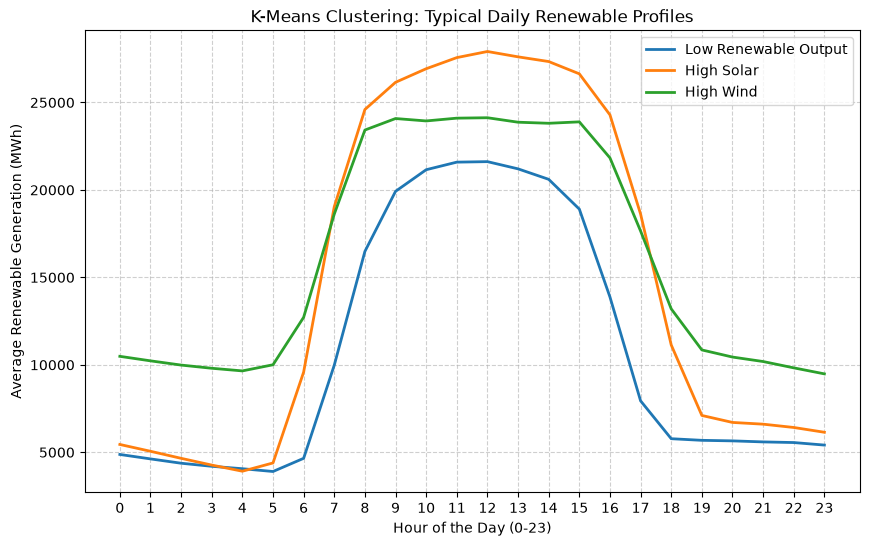

In [28]:
color_map = {
    'High Solar': 'tab:orange',
    'High Wind': 'tab:green',
    'Low Renewable Output': 'tab:blue'
}

plt.figure(figsize=(10, 6))

for cluster_id, name in cluster_names.items():
    cluster_data = daily_profiles[daily_profiles['cluster'] == cluster_id]
    mean_profile = cluster_data.drop(columns=['cluster', 'cluster_name']).mean()
    plt.plot(
        mean_profile.index, 
        mean_profile.values, 
        label=name, 
        color=color_map[name], 
        linewidth=2
    )

plt.title('K-Means Clustering: Typical Daily Renewable Profiles')
plt.xlabel('Hour of the Day (0-23)')
plt.ylabel('Average Renewable Generation (MWh)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Unsupervised Learning: Market Regimes via K-Means
* **High Solar:** Days characterized by extreme solar generation during central hours (peaking near 28,000 MWh). These days drive the deepest midday price drops.
* **High Wind:** Days with consistent overnight wind generation (~10,000 MWh baseline) that keeps market prices lower 24/7, combined with a standard midday solar boost.
* **Low Renewable Output:** Days with the lowest overall renewable contribution. This regime forces a higher reliance on expensive fossil fuels, resulting in higher market prices and volatility.

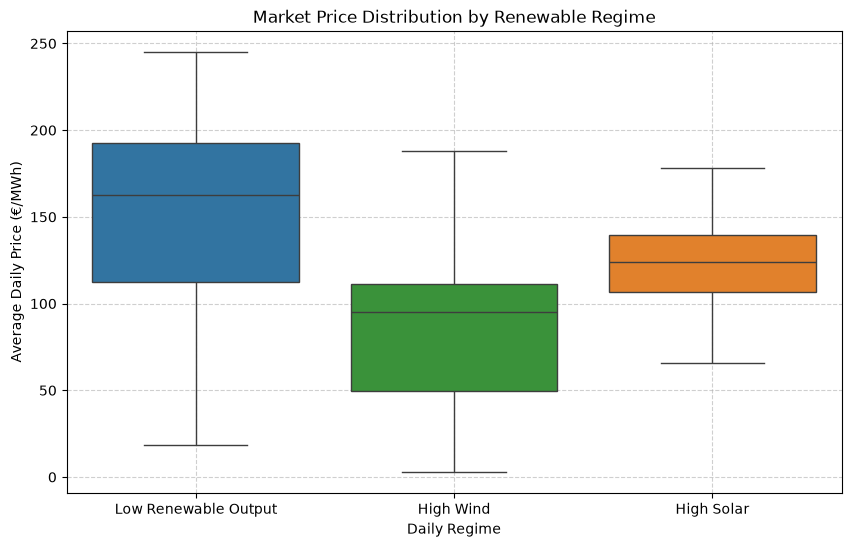

In [29]:
# Calculate daily average prices
daily_prices = df.groupby('date')['price_eur_mwh'].mean().rename('avg_price')

# Merge prices with our clustered profiles
cluster_analysis = daily_profiles[['cluster_name']].join(daily_prices).dropna()

plt.figure(figsize=(10, 6))
sns.boxplot(
    x='cluster_name', 
    y='avg_price', 
    data=cluster_analysis,
    hue='cluster_name',
    palette=color_map,
    order=['Low Renewable Output', 'High Wind', 'High Solar'],
    legend=False
)

plt.title('Market Price Distribution by Renewable Regime')
plt.xlabel('Daily Regime')
plt.ylabel('Average Daily Price (€/MWh)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Economic Impact by Renewable Regime
* **Low Renewable Output:** Exhibits the highest median daily price (approx. 160 €/MWh) and extreme maximums near 250 €/MWh. This visually confirms that heavy reliance on fossil fuels drives both high costs and high volatility.
* **High Wind:** Delivers the lowest median price (under 100 €/MWh) and pushes minimum daily averages down near 0 €/MWh. Consistent 24/7 generation effectively depresses overall base prices.
* **High Solar:** Shows a moderate median price (~125 €/MWh) with a much tighter variance. While midday solar crashes the price to zero, the expensive evening ramp-up pulls the overall daily average back up.